# Animar una trayectoria sobre el mapa energético

El marcador recorre el paisaje energético usando las posiciones y estados almacenados en la trayectoria. El valor de q se proporciona mediante un diccionario explícito, dado que el simulador cinético actual no calcula una coordenada conformacional continua.

In [1]:
from pathlib import Path
import sys

# Find the project root whether JupyterLab was launched from the repository
# root or from the notebooks/ folder.
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in candidates if (path / "src" / "protein_motor_sim").is_dir()),
    None,
)
if PROJECT_ROOT is not None:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

print("Project root:", PROJECT_ROOT or "package expected to be installed in this kernel")

Project root: /home/zix/ProteinMotorSim


## 1. Simulación y superficie

In [2]:
from protein_motor_sim import Environment, GillespieSimulator, Kinesin1
from protein_motor_sim.mechanics.energy_landscape import EnergyLandscape

trajectory = GillespieSimulator().run(
    Kinesin1(), Environment(atp_concentration=1.0e-3), t_max=0.18, seed=9
)
landscape = EnergyLandscape(
    spatial_barrier_kBT=2.2,
    conformational_barrier_kBT=2.8,
    opposing_force_pN=0.5,
)
state_coordinates = {
    "bound_apo": 0.0,
    "atp_bound": 0.35,
    "post_hydrolysis": 1.0,
    "detached": 0.5,
}
print(f"Number of trajectory records: {len(trajectory.times_s)}")

Number of trajectory records: 27


## 2. Animar el avance sobre el mapa

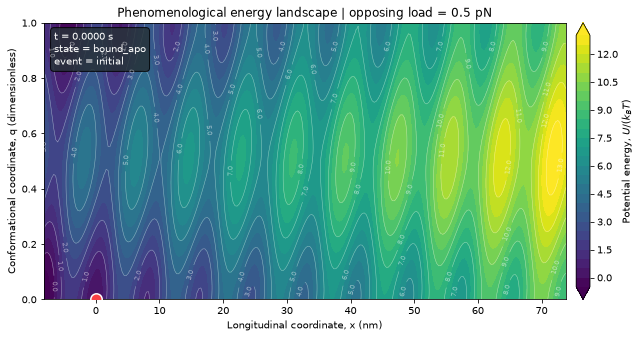

In [3]:
from IPython.display import HTML, display
from protein_motor_sim.visualization.energy_maps import animate_trajectory_on_energy_landscape

energy_animation = animate_trajectory_on_energy_landscape(
    trajectory,
    landscape,
    state_coordinates=state_coordinates,
    interval_ms=100,
)
display(HTML(energy_animation.to_jshtml()))